In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.model_selection import cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import shap

In [2]:
df = pd.read_csv('../../datasets/balanceados/dataset_fluxo_balanceado.csv')
print(df['Label'].value_counts())
print("\n")
print(df.info())

Label
0    52402
1    52400
Name: count, dtype: int64


<class 'pandas.DataFrame'>
RangeIndex: 104802 entries, 0 to 104801
Data columns (total 22 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Total Fwd Packets            104802 non-null  int64  
 1   Total Backward Packets       104802 non-null  int64  
 2   Total Length of Fwd Packets  104802 non-null  float64
 3   Total Length of Bwd Packets  104802 non-null  float64
 4   Flow Bytes/s                 104802 non-null  float64
 5   Flow Packets/s               104802 non-null  float64
 6   Flow IAT Mean                104802 non-null  float64
 7   Flow IAT Std                 104802 non-null  float64
 8   Flow IAT Max                 104802 non-null  float64
 9   Flow IAT Min                 104802 non-null  float64
 10  Fwd Packets/s                104802 non-null  float64
 11  Bwd Packets/s                104802 non-null  float64
 12  Packet Length

In [4]:
x=df.drop(columns=['Label'])
y=df['Label']

x_treino, x_teste, y_treino, y_teste = train_test_split(x, y, test_size=0.2, random_state=42)

scaler = StandardScaler().set_output(transform="pandas")
x_treino_scaled = scaler.fit_transform(x_treino)   
x_teste_scaled = scaler.transform(x_teste)

amostra_500 = x_teste_scaled.sample(n=500, random_state=42)
amostra_100 = x_teste_scaled.sample(n=100, random_state=42)

Decision Tree

In [5]:
modelo_dt = tree.DecisionTreeClassifier(random_state=42)
modelo_dt.fit(x_treino_scaled, y_treino)
y_pred_dt = modelo_dt.predict(x_teste_scaled)
y_pred_dttreino = modelo_dt.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_dttreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia = accuracy_score(y_teste, y_pred_dt)
precisao = precision_score(y_teste, y_pred_dt, average='macro')
recall = recall_score(y_teste, y_pred_dt, average='macro')
f1 = f1_score(y_teste, y_pred_dt, average='macro')
matriz_dt1 = confusion_matrix(y_teste, y_pred_dt)

matriz_confusao_dt1 = pd.DataFrame(
    matriz_dt1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt1 = matriz_confusao_dt1.div(matriz_confusao_dt1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia*100):.4f}")
print(f"Precisão:  {(precisao*100):.4f}")
print(f"Recall:    {(recall*100):.4f}")
print(f"F1-Score:  {(f1*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Holdout):")
print((( matriz_normalizada_dt1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9893
Acurácia:  98.6880
Precisão:  98.7002
Recall:    98.6830
F1-Score:  98.6878

                       MATRIZ DE CONFUSÃO(DT- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.05%                1.95%
Real: 1 (Ataque)                0.68%               99.32%


In [7]:
modelo_dt_kfold = make_pipeline(StandardScaler(), tree.DecisionTreeClassifier(max_depth=9, random_state=42))
metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

y_pred_kfold_dt = cross_val_predict(modelo_dt_kfold, x, y, cv=5)
matriz_dt2 = confusion_matrix(y, y_pred_kfold_dt)

resultados_kfold_dt = cross_validate(modelo_dt_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_dt = resultados_kfold_dt['test_accuracy'].mean()
precisao_kfold_dt = resultados_kfold_dt['test_precision_macro'].mean()
recall_kfold_dt = resultados_kfold_dt['test_recall_macro'].mean()
f1_kfold_dt = resultados_kfold_dt['test_f1_macro'].mean()

matriz_confusao_dt2 = pd.DataFrame(
    matriz_dt2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_dt2 = matriz_confusao_dt2.div(matriz_confusao_dt2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_dt*100):.4f}")
print(f"Precisão:  {(precisao_kfold_dt*100):.4f}")
print(f"Recall:    {(recall_kfold_dt*100):.4f}")
print(f"F1-Score:  {(f1_kfold_dt*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(DT- Kfold):")
print((( matriz_normalizada_dt2)*100).round(2).astype(str) + '%')

Acurácia:  98.6727
Precisão:  98.6819
Recall:    98.6727
F1-Score:  98.6727

                       MATRIZ DE CONFUSÃO(DT- Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               97.99%                2.01%
Real: 1 (Ataque)                0.65%               99.35%


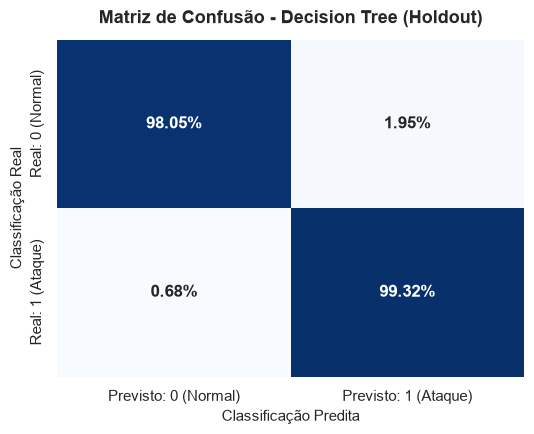

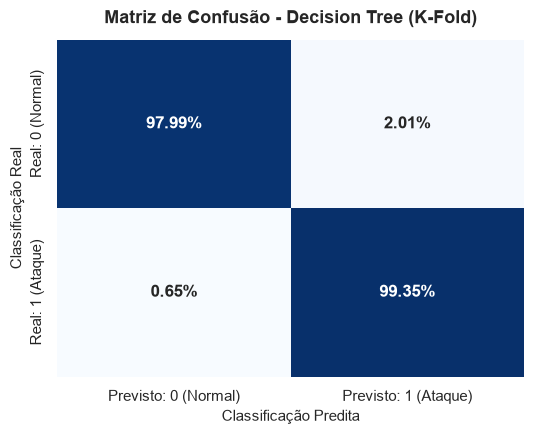

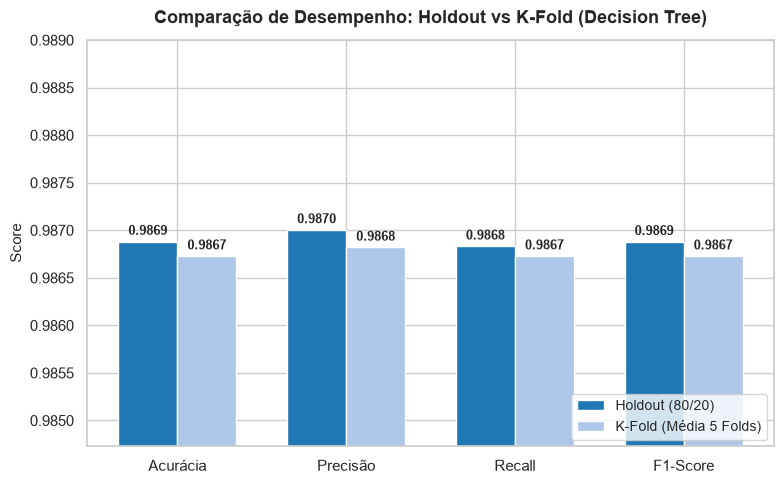

In [ ]:
sns.set_theme(style="whitegrid")

matriz_pct_dt1 = matriz_normalizada_dt1.values * 100
labels_dt1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_dt1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_dt1, annot=labels_dt1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - Decision Tree (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_dt2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - Decision Tree (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia, precisao, recall, f1]
valores_kfold = [
    resultados_kfold_dt['test_accuracy'].mean(),
    resultados_kfold_dt['test_precision_macro'].mean(),
    resultados_kfold_dt['test_recall_macro'].mean(),
    resultados_kfold_dt['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color='#1f77b4')
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color='#aec7e8')

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (Decision Tree)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

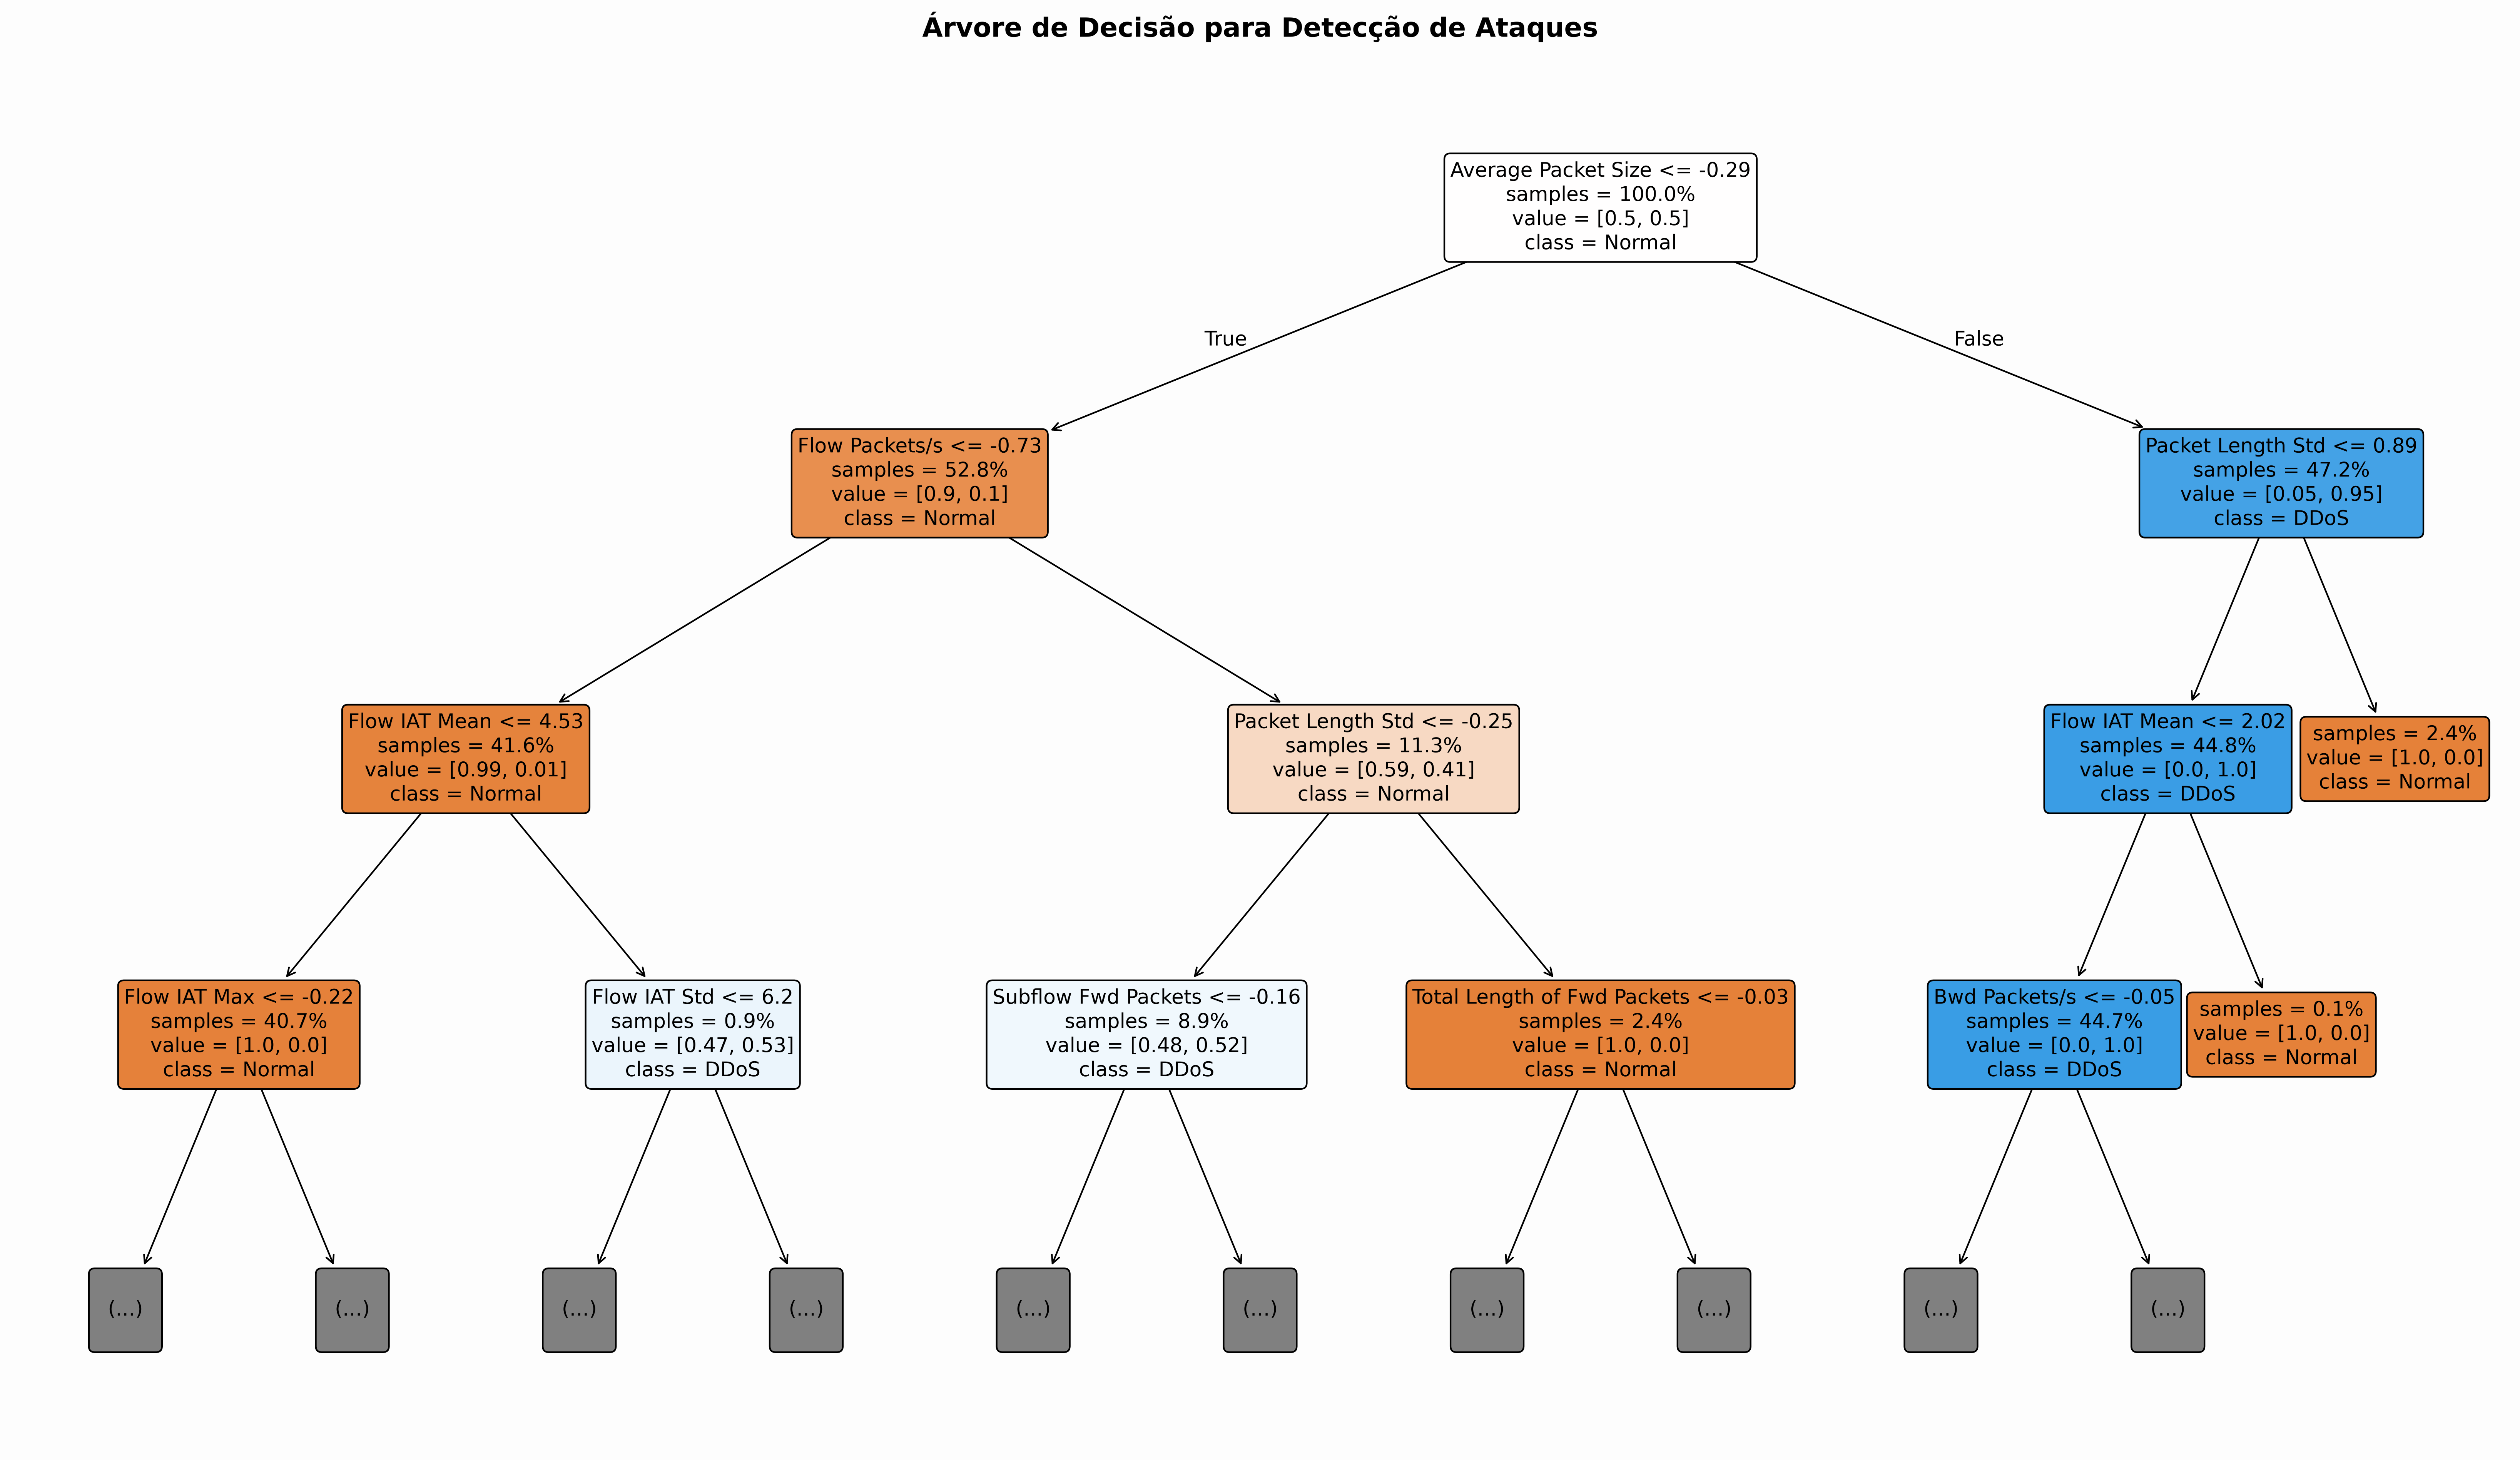

In [ ]:
fig, ax = plt.subplots(figsize=(27, 15), dpi=310)
fig.patch.set_facecolor('#fdfdfd') 

tree.plot_tree(
    modelo_dt, 
    max_depth=3,
    feature_names=x.columns.tolist(),
    filled=True, 
    class_names=['Normal', 'DDoS'],
    fontsize=12,
    rounded=True, 
    precision=2,
    impurity=False,
    proportion=True
)

ax.axis('off') 
plt.title("Árvore de Decisão para Detecção de Ataques", fontsize=16, fontweight='bold', pad=20)

plt.show()

Random Forest

In [8]:
modelo_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
modelo_rf.fit(x_treino_scaled, y_treino)
y_pred_rf = modelo_rf.predict(x_teste_scaled)
y_pred_rftreino = modelo_rf.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_rftreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_rf = accuracy_score(y_teste, y_pred_rf)
precisao_rf = precision_score(y_teste, y_pred_rf, average='macro')
recall_rf = recall_score(y_teste, y_pred_rf, average='macro')
f1_rf = f1_score(y_teste, y_pred_rf, average='macro')
matriz_rf1 = confusion_matrix(y_teste, y_pred_rf)

matriz_confusao_rf1 = pd.DataFrame(
    matriz_rf1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf1 = matriz_confusao_rf1.div(matriz_confusao_rf1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_rf*100):.4f}")
print(f"Precisão:  {(precisao_rf*100):.4f}")
print(f"Recall:    {(recall_rf*100):.4f}")
print(f"F1-Score:  {(f1_rf*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(RF- Holdout):")
print((( matriz_normalizada_rf1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9892
Acurácia:  98.7024
Precisão:  98.7141
Recall:    98.6975
F1-Score:  98.7021

                       MATRIZ DE CONFUSÃO(RF- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.08%                1.92%
Real: 1 (Ataque)                0.68%               99.32%


In [ ]:
modelo_rf_kfold = make_pipeline(StandardScaler(),RandomForestClassifier(random_state=42, n_jobs=-1))

metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

resultados_kfold_rf = cross_validate(modelo_rf_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_rf = resultados_kfold_rf['test_accuracy'].mean()
precisao_kfold_rf = resultados_kfold_rf['test_precision_macro'].mean()
recall_kfold_rf = resultados_kfold_rf['test_recall_macro'].mean()
f1_kfold_rf = resultados_kfold_rf['test_f1_macro'].mean()

y_pred_kfold_rf = cross_val_predict(modelo_rf_kfold, x, y, cv=5)
matriz_rf2 = confusion_matrix(y, y_pred_kfold_rf)

matriz_confusao_rf2 = pd.DataFrame(
    matriz_rf2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_rf2 = matriz_confusao_rf2.div(matriz_confusao_rf2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_rf*100):.4f}%")
print(f"Precisão:  {(precisao_kfold_rf*100):.4f}%")
print(f"Recall:    {(recall_kfold_rf*100):.4f}%")
print(f"F1-Score:  {(f1_kfold_rf*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (RF - Kfold):")
print(((matriz_normalizada_rf2)*100).round(2).astype(str) + '%')

Acurácia:  98.7958%
Precisão:  98.8066%
Recall:    98.7958%
F1-Score:  98.7958%

                   MATRIZ DE CONFUSÃO (RF - Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.06%                1.94%
Real: 1 (Ataque)                0.47%               99.53%


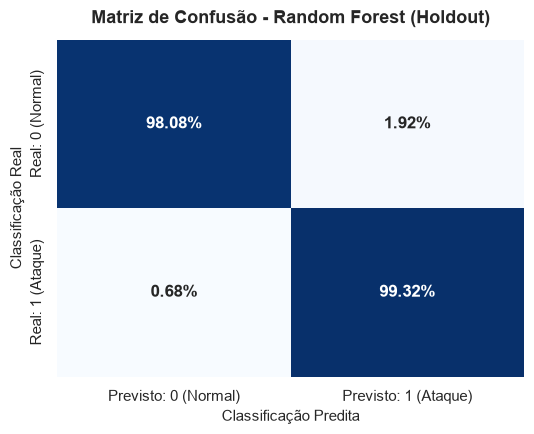

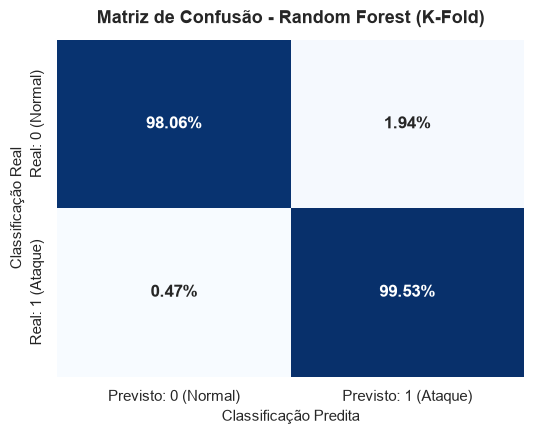

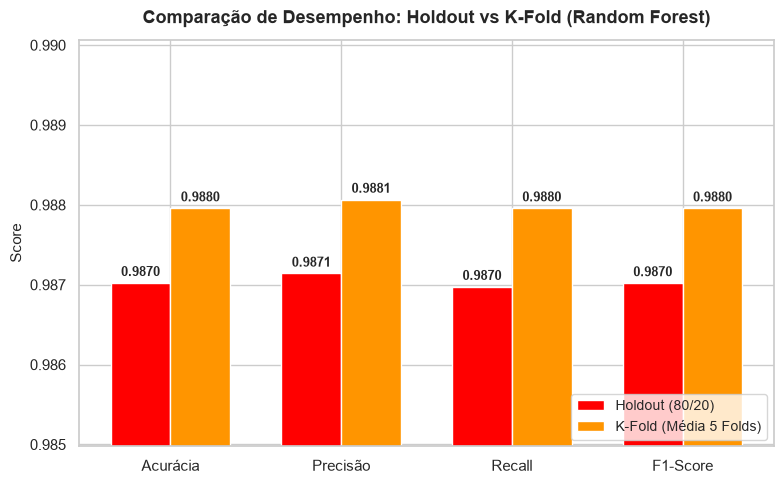

In [ ]:
matriz_pct_rf1 = matriz_normalizada_rf1.values * 100
labels_rf1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_rf1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_rf1, annot=labels_rf1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - Random Forest (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_rf2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - Random Forest (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_rf, precisao_rf, recall_rf, f1_rf]
valores_kfold = [
    resultados_kfold_rf['test_accuracy'].mean(),
    resultados_kfold_rf['test_precision_macro'].mean(),
    resultados_kfold_rf['test_recall_macro'].mean(),
    resultados_kfold_rf['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#FF0000")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#ff9500")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (Random Forest)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

Rede Neural

In [9]:
modelo_mlp = MLPClassifier(random_state=42, max_iter=300)
modelo_mlp.fit(x_treino_scaled, y_treino)
y_pred_mlp = modelo_mlp.predict(x_teste_scaled)
y_pred_mlptreino = modelo_mlp.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_mlptreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_mlp = accuracy_score(y_teste, y_pred_mlp)
precisao_mlp = precision_score(y_teste, y_pred_mlp, average='macro')
recall_mlp = recall_score(y_teste, y_pred_mlp, average='macro')
f1_mlp = f1_score(y_teste, y_pred_mlp, average='macro')
matriz_mlp1 = confusion_matrix(y_teste, y_pred_mlp)

matriz_confusao_mlp1 = pd.DataFrame(
    matriz_mlp1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp1 = matriz_confusao_mlp1.div(matriz_confusao_mlp1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_mlp*100):.4f}")
print(f"Precisão:  {(precisao_mlp*100):.4f}")
print(f"Recall:    {(recall_mlp*100):.4f}")
print(f"F1-Score:  {(f1_mlp*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(MLP- Holdout):")
print((( matriz_normalizada_mlp1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9864
Acurácia:  98.5545
Precisão:  98.5672
Recall:    98.5493
F1-Score:  98.5542

                       MATRIZ DE CONFUSÃO(MLP- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               97.89%                2.11%
Real: 1 (Ataque)                 0.8%                99.2%


In [10]:
modelo_mlp_kfold = make_pipeline(StandardScaler(),MLPClassifier(random_state=42, max_iter=300))

metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

resultados_kfold_mlp = cross_validate(modelo_mlp_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_mlp = resultados_kfold_mlp['test_accuracy'].mean()
precisao_kfold_mlp = resultados_kfold_mlp['test_precision_macro'].mean()
recall_kfold_mlp = resultados_kfold_mlp['test_recall_macro'].mean()
f1_kfold_mlp = resultados_kfold_mlp['test_f1_macro'].mean()

y_pred_kfold_mlp = cross_val_predict(modelo_mlp_kfold, x, y, cv=5)
matriz_mlp2 = confusion_matrix(y, y_pred_kfold_mlp)

matriz_confusao_mlp2 = pd.DataFrame(
    matriz_mlp2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_mlp2 = matriz_confusao_mlp2.div(matriz_confusao_mlp2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_mlp*100):.4f}%")
print(f"Precisão:  {(precisao_kfold_mlp*100):.4f}%")
print(f"Recall:    {(recall_kfold_mlp*100):.4f}%")
print(f"F1-Score:  {(f1_kfold_mlp*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (MLP - Kfold):")
print(((matriz_normalizada_mlp2)*100).round(2).astype(str) + '%')


c:\Users\jvesc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


Acurácia:  98.6231%
Precisão:  98.6347%
Recall:    98.6231%
F1-Score:  98.6230%

                   MATRIZ DE CONFUSÃO (MLP - Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               97.79%                2.21%
Real: 1 (Ataque)                0.62%               99.38%


c:\Users\jvesc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:792: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


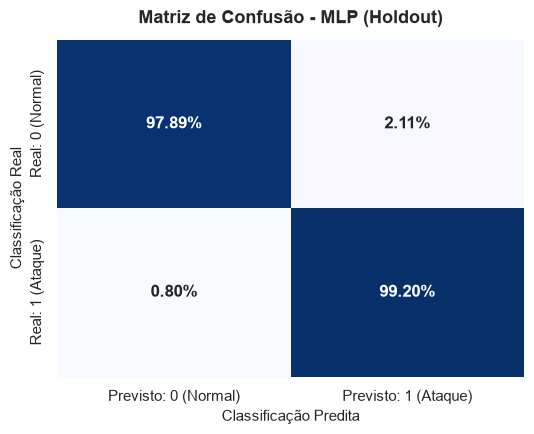

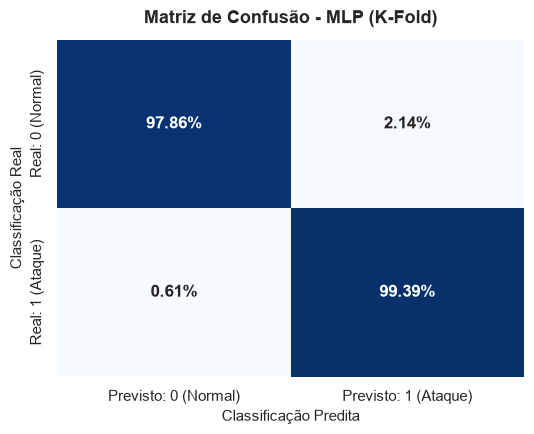

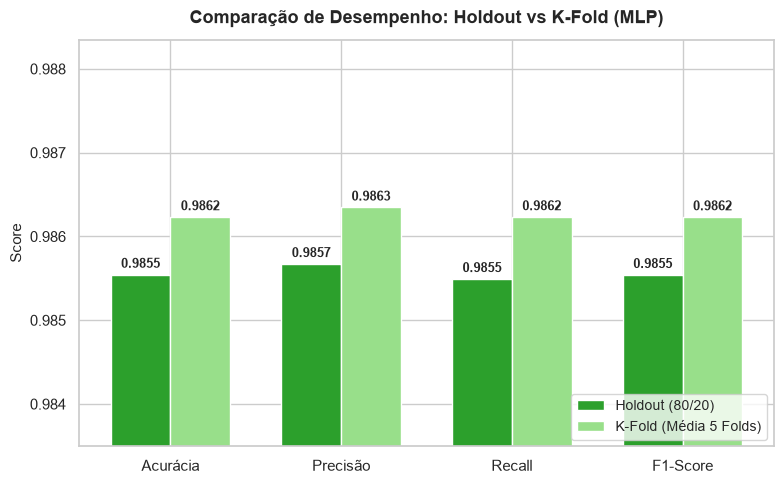

In [ ]:
matriz_pct_mlp1 = matriz_normalizada_mlp1.values * 100
labels_mlp1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_mlp1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_mlp1, annot=labels_mlp1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - MLP (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_mlp2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - MLP (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_mlp, precisao_mlp, recall_mlp, f1_mlp]
valores_kfold = [
    resultados_kfold_mlp['test_accuracy'].mean(),
    resultados_kfold_mlp['test_precision_macro'].mean(),
    resultados_kfold_mlp['test_recall_macro'].mean(),
    resultados_kfold_mlp['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#2ca02c")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#98df8a")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (MLP)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

SVM

In [11]:
modelo_svm = LinearSVC(random_state=42, max_iter=2000);
modelo_svm.fit(x_treino_scaled, y_treino)
y_pred_svm = modelo_svm.predict(x_teste_scaled)
y_pred_svmtreino = modelo_svm.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_svmtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_svm = accuracy_score(y_teste, y_pred_svm)
precisao_svm = precision_score(y_teste, y_pred_svm, average='macro')
recall_svm = recall_score(y_teste, y_pred_svm, average='macro')
f1_svm = f1_score(y_teste, y_pred_svm, average='macro')
matriz_svm1 = confusion_matrix(y_teste, y_pred_svm)

matriz_confusao_svm1 = pd.DataFrame(
    matriz_svm1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm1 = matriz_confusao_svm1.div(matriz_confusao_svm1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_svm*100):.4f}")
print(f"Precisão:  {(precisao_svm*100):.4f}")
print(f"Recall:    {(recall_svm*100):.4f}")
print(f"F1-Score:  {(f1_svm*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(SVM- Holdout):")
print((( matriz_normalizada_svm1)*100).round(2).astype(str) + '%')



Acurácia no conjunto de treino: 0.9727
Acurácia:  97.2139
Precisão:  97.2200
Recall:    97.2199
F1-Score:  97.2139

                       MATRIZ DE CONFUSÃO(SVM- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               97.99%                2.01%
Real: 1 (Ataque)                3.55%               96.45%


In [ ]:
modelo_svm_kfold = make_pipeline(StandardScaler(),LinearSVC(random_state=42, max_iter=2000, dual=False))

metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

resultados_kfold_svm = cross_validate(modelo_svm_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_svm = resultados_kfold_svm['test_accuracy'].mean()
precisao_kfold_svm = resultados_kfold_svm['test_precision_macro'].mean()
recall_kfold_svm = resultados_kfold_svm['test_recall_macro'].mean()
f1_kfold_svm = resultados_kfold_svm['test_f1_macro'].mean()

y_pred_kfold_svm = cross_val_predict(modelo_svm_kfold, x, y, cv=5)
matriz_svm2 = confusion_matrix(y, y_pred_kfold_svm)

matriz_confusao_svm2 = pd.DataFrame(
    matriz_svm2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_svm2 = matriz_confusao_svm2.div(matriz_confusao_svm2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_svm*100):.4f}%")
print(f"Precisão:  {(precisao_kfold_svm*100):.4f}%")
print(f"Recall:    {(recall_kfold_svm*100):.4f}%")
print(f"F1-Score:  {(f1_kfold_svm*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (SVM - Kfold):")
print(((matriz_normalizada_svm2)*100).round(2).astype(str) + '%')


Acurácia:  97.2300%
Precisão:  97.2369%
Recall:    97.2300%
F1-Score:  97.2299%

                   MATRIZ DE CONFUSÃO (SVM - Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               97.82%                2.18%
Real: 1 (Ataque)                3.36%               96.64%


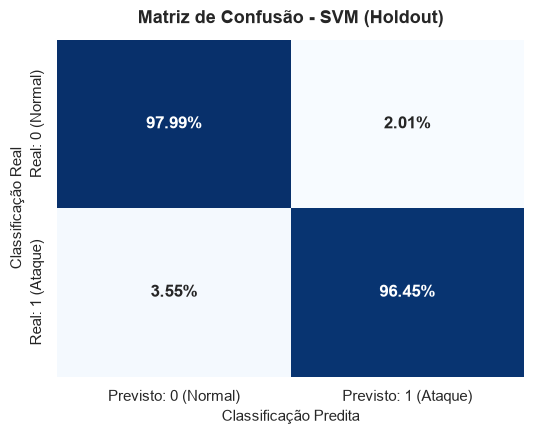

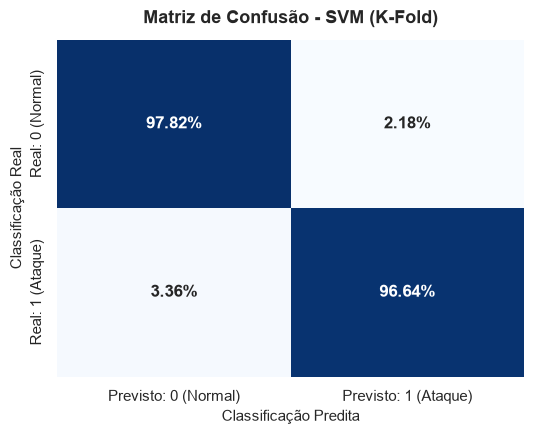

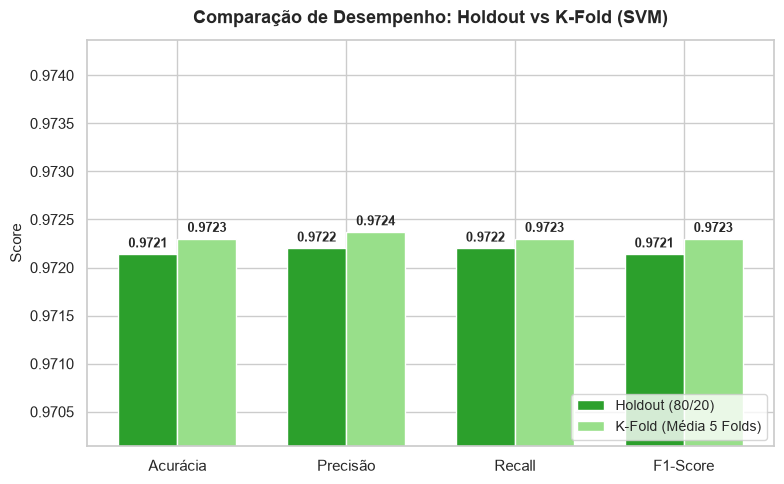

In [ ]:
matriz_pct_svm1 = matriz_normalizada_svm1.values * 100
labels_svm1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_svm1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_svm1, annot=labels_svm1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - SVM (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_svm2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - SVM (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_svm, precisao_svm, recall_svm, f1_svm]
valores_kfold = [
    resultados_kfold_svm['test_accuracy'].mean(),
    resultados_kfold_svm['test_precision_macro'].mean(),
    resultados_kfold_svm['test_recall_macro'].mean(),
    resultados_kfold_svm['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#2ca02c")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#98df8a")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (SVM)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

KNN

In [12]:
modelo_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
modelo_knn.fit(x_treino_scaled, y_treino)
y_pred_knn = modelo_knn.predict(x_teste_scaled)
y_pred_knntreino = modelo_knn.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_knntreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_knn = accuracy_score(y_teste, y_pred_knn)
precisao_knn = precision_score(y_teste, y_pred_knn, average='macro')
recall_knn = recall_score(y_teste, y_pred_knn, average='macro')
f1_knn = f1_score(y_teste, y_pred_knn, average='macro')
matriz_knn1 = confusion_matrix(y_teste, y_pred_knn)

matriz_confusao_knn1 = pd.DataFrame(
    matriz_knn1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn1 = matriz_confusao_knn1.div(matriz_confusao_knn1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_knn*100):.4f}%")
print(f"Precisão:  {(precisao_knn*100):.4f}%")
print(f"Recall:    {(recall_knn*100):.4f}%")
print(f"F1-Score:  {(f1_knn*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (KNN - Holdout):")
print(((matriz_normalizada_knn1)*100).round(2).astype(str) + '%')

Acurácia no conjunto de treino: 0.9877
Acurácia:  98.6022%
Precisão:  98.6152%
Recall:    98.5969%
F1-Score:  98.6019%

                   MATRIZ DE CONFUSÃO (KNN - Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               97.93%                2.07%
Real: 1 (Ataque)                0.74%               99.26%


In [ ]:
modelo_knn_kfold = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5, n_jobs=-1))
metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

y_pred_kfold_knn = cross_val_predict(modelo_knn_kfold, x, y, cv=5)
matriz_knn2 = confusion_matrix(y, y_pred_kfold_knn)

resultados_kfold_knn = cross_validate(modelo_knn_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_knn = resultados_kfold_knn['test_accuracy'].mean()
precisao_kfold_knn = resultados_kfold_knn['test_precision_macro'].mean()
recall_kfold_knn = resultados_kfold_knn['test_recall_macro'].mean()
f1_kfold_knn = resultados_kfold_knn['test_f1_macro'].mean()

matriz_confusao_knn2 = pd.DataFrame(
    matriz_knn2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_knn2 = matriz_confusao_knn2.div(matriz_confusao_knn2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_knn*100):.4f}")
print(f"Precisão:  {(precisao_kfold_knn*100):.4f}")
print(f"Recall:    {(recall_kfold_knn*100):.4f}")
print(f"F1-Score:  {(f1_kfold_knn*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(KNN- Kfold):")
print(((matriz_normalizada_knn2)*100).round(2).astype(str) + '%')

Acurácia:  98.6517
Precisão:  98.6629
Recall:    98.6518
F1-Score:  98.6517

                       MATRIZ DE CONFUSÃO(KNN- Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)                97.9%                 2.1%
Real: 1 (Ataque)                 0.6%                99.4%


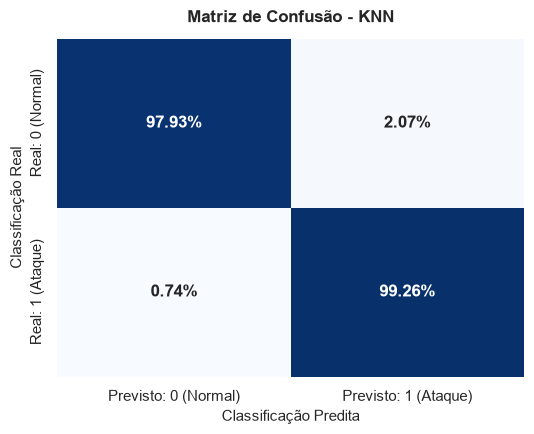

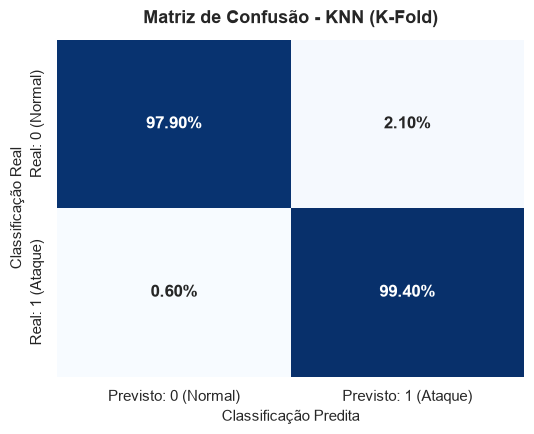

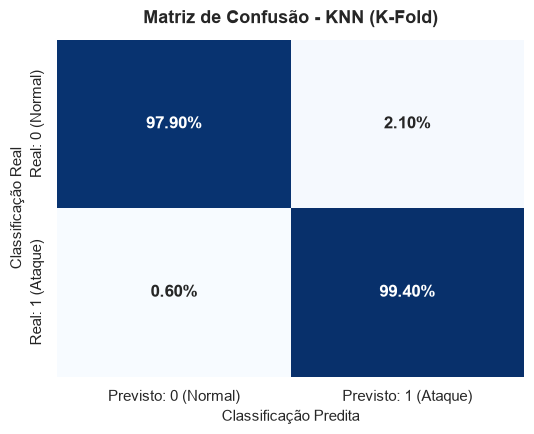

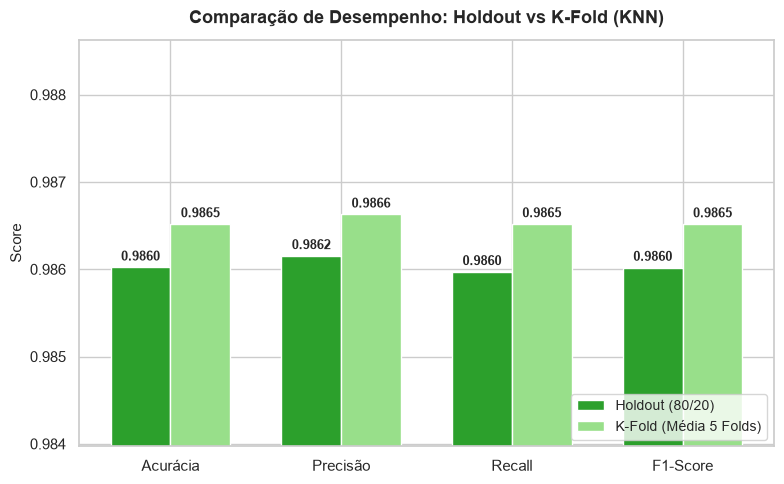

In [ ]:
matriz_pct_knn1 = matriz_normalizada_knn1.values * 100
labels_knn1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_knn1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_knn1, annot=labels_knn1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})
plt.title('Matriz de Confusão - KNN', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

# --- 2. Matriz de Confusão - Holdout Bloco 2 (Pipeline) ---
matriz_porcentagem_kfold = matriz_normalizada_knn2.values * 100
labels_kfold = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_kfold])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_kfold, annot=labels_kfold, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})
plt.title('Matriz de Confusão - KNN (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()


matriz_kfold_ref = matriz_normalizada_knn2

matriz_porcentagem_kfold = matriz_kfold_ref.values * 100
labels_kfold = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_kfold])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_kfold, annot=labels_kfold, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})
plt.title('Matriz de Confusão - KNN (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

# --- 4. Comparação de Desempenho: Holdout vs K-Fold ---
metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

# Coleta direta das variáveis escalares geradas nos blocos
valores_holdout = [acuracia_knn, precisao_knn, recall_knn, f1_knn]
valores_kfold = [acuracia_kfold_knn, precisao_kfold_knn, recall_kfold_knn, f1_kfold_knn]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#2ca02c")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#98df8a")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (KNN)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

XgBOOST

In [13]:
modelo_xgb = xgb.XGBClassifier(random_state=42, n_jobs=-1, eval_metric='logloss')
modelo_xgb.fit(x_treino_scaled, y_treino)
y_pred_xgb = modelo_xgb.predict(x_teste_scaled)
y_pred_xgbtreino = modelo_xgb.predict(x_treino_scaled)

acuracia_treino = accuracy_score(y_treino, y_pred_xgbtreino)
print(f"Acurácia no conjunto de treino: {acuracia_treino:.4f}")

acuracia_xgb = accuracy_score(y_teste, y_pred_xgb)
precisao_xgb = precision_score(y_teste, y_pred_xgb, average='macro')
recall_xgb = recall_score(y_teste, y_pred_xgb, average='macro')
f1_xgb = f1_score(y_teste, y_pred_xgb, average='macro')
matriz_xgb1 = confusion_matrix(y_teste, y_pred_xgb)

matriz_confusao_xgb1 = pd.DataFrame(
    matriz_xgb1, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb1 = matriz_confusao_xgb1.div(matriz_confusao_xgb1.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_xgb*100):.4f}")
print(f"Precisão:  {(precisao_xgb*100):.4f}")
print(f"Recall:    {(recall_xgb*100):.4f}")
print(f"F1-Score:  {(f1_xgb*100):.4f}")
print("\n                       MATRIZ DE CONFUSÃO(XGB- Holdout):")
print((( matriz_normalizada_xgb1)*100).round(2).astype(str) + '%')


Acurácia no conjunto de treino: 0.9889
Acurácia:  98.7071
Precisão:  98.7178
Recall:    98.7025
F1-Score:  98.7069

                       MATRIZ DE CONFUSÃO(XGB- Holdout):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.12%                1.88%
Real: 1 (Ataque)                0.71%               99.29%


In [ ]:
modelo_xgb_kfold = make_pipeline(
    StandardScaler(),
    xgb.XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)
)

metricas_desejadas = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']

resultados_kfold_xgb = cross_validate(modelo_xgb_kfold, x, y, cv=5, scoring=metricas_desejadas)

acuracia_kfold_xgb = resultados_kfold_xgb['test_accuracy'].mean()
precisao_kfold_xgb = resultados_kfold_xgb['test_precision_macro'].mean()
recall_kfold_xgb = resultados_kfold_xgb['test_recall_macro'].mean()
f1_kfold_xgb = resultados_kfold_xgb['test_f1_macro'].mean()

y_pred_kfold_xgb = cross_val_predict(modelo_xgb_kfold, x, y, cv=5)
matriz_xgb2 = confusion_matrix(y, y_pred_kfold_xgb)

matriz_confusao_xgb2 = pd.DataFrame(
    matriz_xgb2, 
    index=['Real: 0 (Normal)', 'Real: 1 (Ataque)'], 
    columns=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)']
)
matriz_normalizada_xgb2 = matriz_confusao_xgb2.div(matriz_confusao_xgb2.sum(axis=1), axis=0)

print(f"Acurácia:  {(acuracia_kfold_xgb*100):.4f}%")
print(f"Precisão:  {(precisao_kfold_xgb*100):.4f}%")
print(f"Recall:    {(recall_kfold_xgb*100):.4f}%")
print(f"F1-Score:  {(f1_kfold_xgb*100):.4f}%")
print("\n                   MATRIZ DE CONFUSÃO (XGB - Kfold):")
print(((matriz_normalizada_xgb2)*100).round(2).astype(str) + '%')

Acurácia:  98.7949%
Precisão:  98.8058%
Recall:    98.7949%
F1-Score:  98.7948%

                   MATRIZ DE CONFUSÃO (XGB - Kfold):
                 Previsto: 0 (Normal) Previsto: 1 (Ataque)
Real: 0 (Normal)               98.05%                1.95%
Real: 1 (Ataque)                0.46%               99.54%


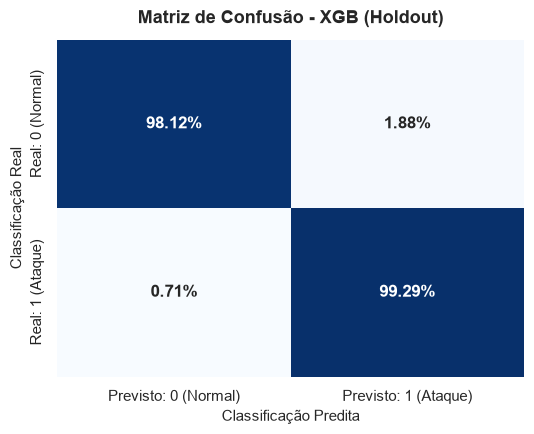

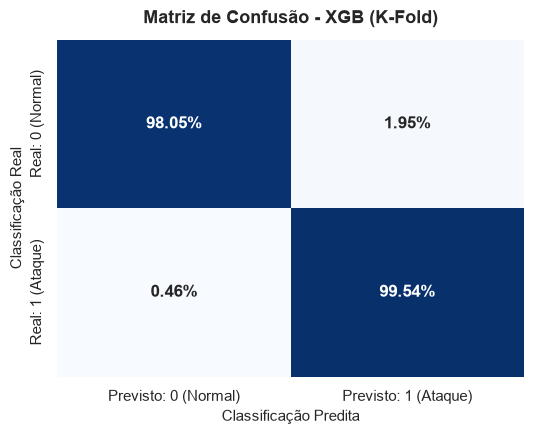

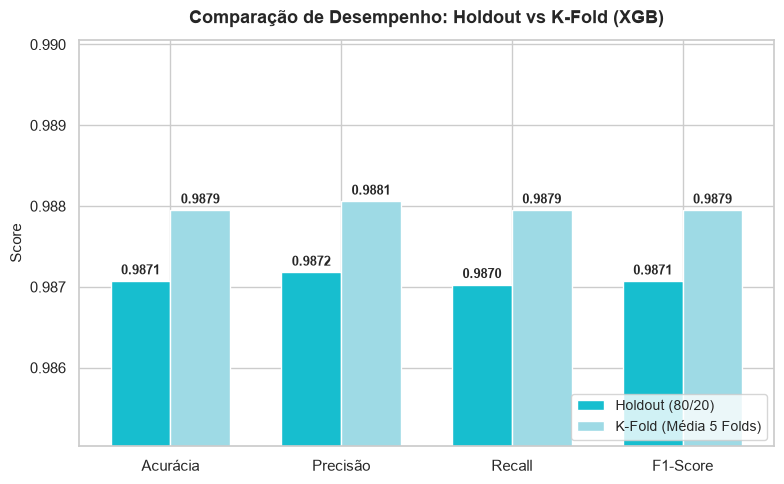

In [ ]:
matriz_pct_xgb1 = matriz_normalizada_xgb1.values * 100
labels_xgb1 = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_pct_xgb1])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_pct_xgb1, annot=labels_xgb1, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - XGB (Holdout)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

matriz_porcentagem_valores = matriz_normalizada_xgb2.values * 100

labels_customizados = np.array([[f"{valor:.2f}%" for valor in linha] for linha in matriz_porcentagem_valores])

plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(matriz_porcentagem_valores, annot=labels_customizados, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Previsto: 0 (Normal)', 'Previsto: 1 (Ataque)'],
            yticklabels=['Real: 0 (Normal)', 'Real: 1 (Ataque)'],
            annot_kws={"size": 12, "weight": "bold"})

plt.title('Matriz de Confusão - XGB (K-Fold)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Classificação Predita', fontsize=11)
plt.ylabel('Classificação Real', fontsize=11)
plt.tight_layout()
plt.show()

metricas_nomes = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']

valores_holdout = [acuracia_xgb, precisao_xgb, recall_xgb, f1_xgb]
valores_kfold = [
    resultados_kfold_xgb['test_accuracy'].mean(),
    resultados_kfold_xgb['test_precision_macro'].mean(),
    resultados_kfold_xgb['test_recall_macro'].mean(),
    resultados_kfold_xgb['test_f1_macro'].mean()
]

x_indices = np.arange(len(metricas_nomes))
largura_barra = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

barras_ho = ax.bar(x_indices - largura_barra/2, valores_holdout, largura_barra, label='Holdout (80/20)', color="#17becf")
barras_kf = ax.bar(x_indices + largura_barra/2, valores_kfold, largura_barra, label='K-Fold (Média 5 Folds)', color="#9edae5")

ax.set_title('Comparação de Desempenho: Holdout vs K-Fold (XGB)', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x_indices)
ax.set_xticklabels(metricas_nomes, fontsize=11)
ax.set_ylabel('Score', fontsize=11)

min_valor = min(min(valores_holdout), min(valores_kfold)) - 0.002
max_valor = max(max(valores_holdout), max(valores_kfold)) + 0.002
ax.set_ylim(min_valor, max_valor)

ax.legend(loc='lower right', fontsize=10)

for barra in barras_ho + barras_kf:
    height = barra.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(barra.get_x() + barra.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

IA explicavel - SHAP

Decision Tree

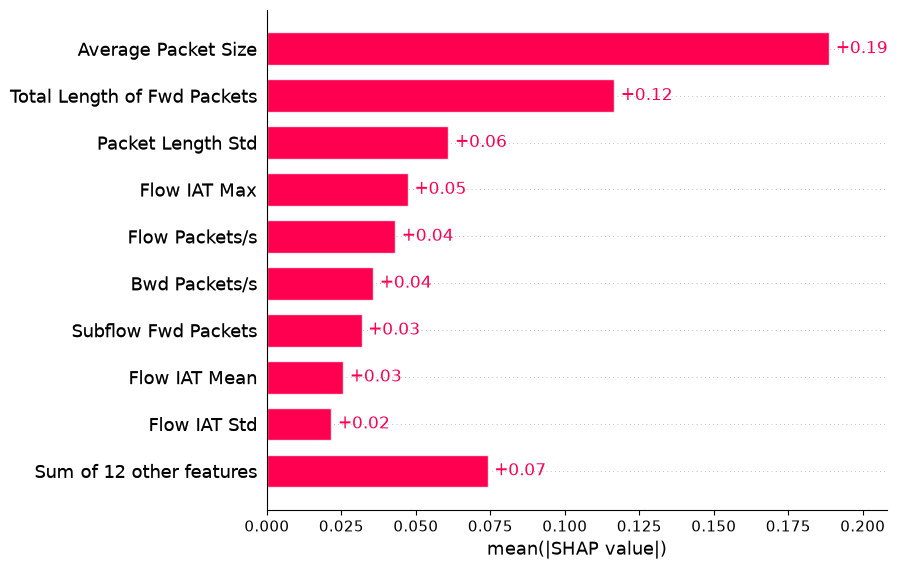

In [14]:
explainer_dt = shap.TreeExplainer(modelo_dt)
shap_values_dt = explainer_dt(amostra_500)

shap.plots.bar(shap_values_dt[:, :, 1])

Random Forest

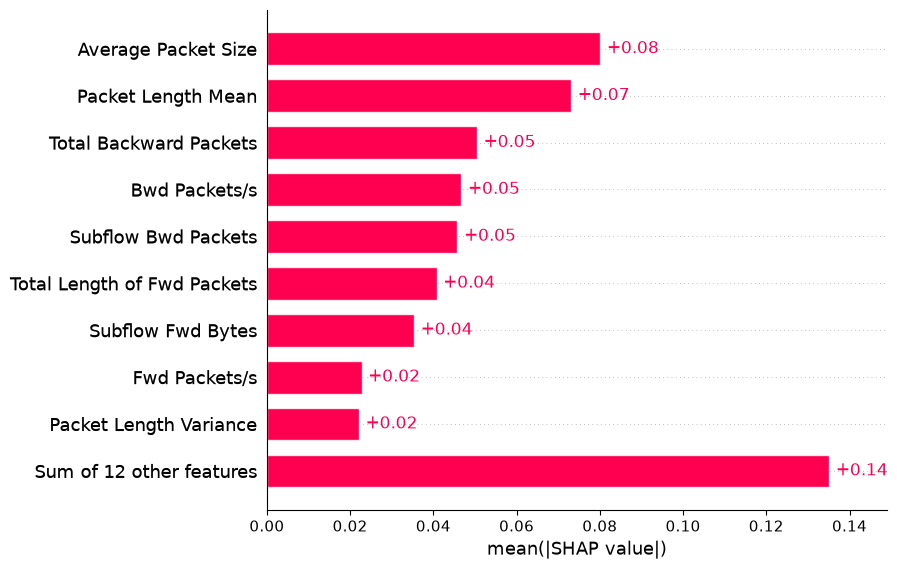

In [16]:
explainer_rf = shap.TreeExplainer(modelo_rf)
shap_values_rf = explainer_rf(amostra_500)        

shap.plots.bar(shap_values_rf[:, :, 1])

XGBoost

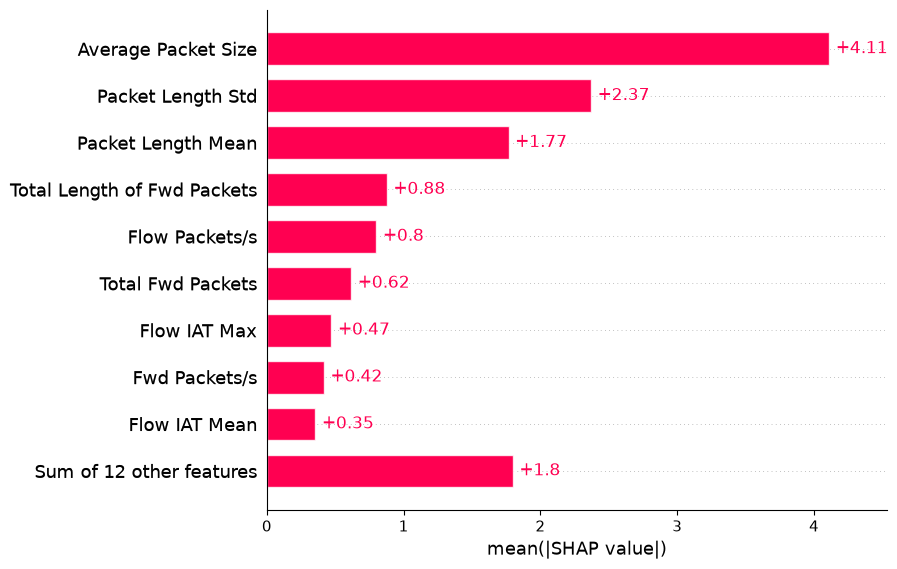

In [18]:
explainer_xgb = shap.TreeExplainer(modelo_xgb)
shap_values_xgb = explainer_xgb(amostra_500)

shap.plots.bar(shap_values_xgb)

SVM

Background dataset has 83841 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=83841 when initializing the masker.


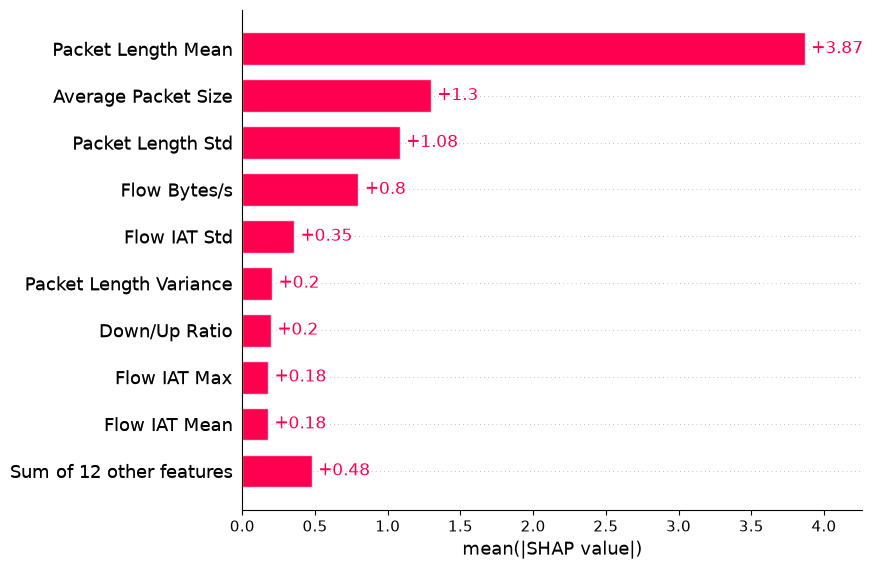

In [ ]:
explainer = shap.LinearExplainer(modelo_svm, x_treino_scaled)
shap_values_svm = explainer(amostra_500)

shap.plots.bar(shap_values_svm)                   

KNN

PermutationExplainer explainer: 101it [03:34,  2.31s/it]                         


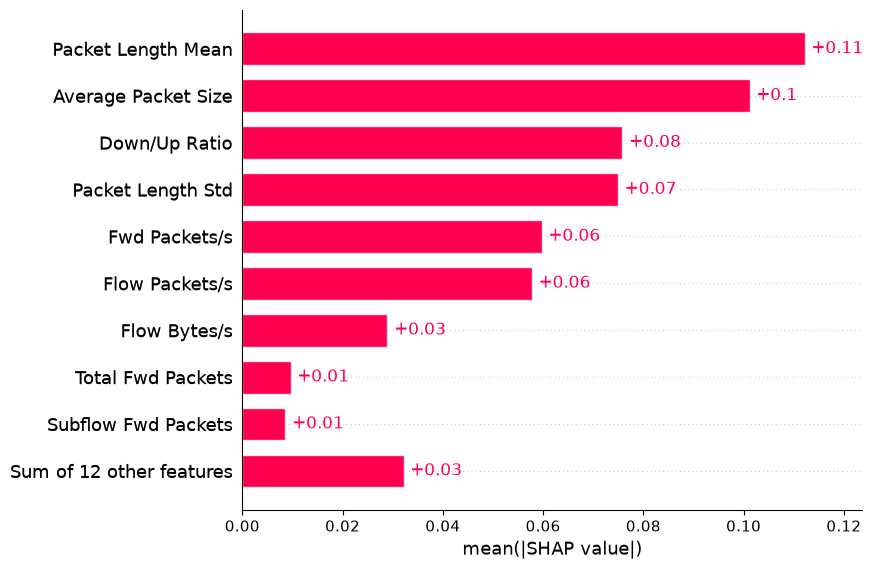

In [23]:
explainer_knn = shap.PermutationExplainer(modelo_knn.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values_knn = explainer_knn(amostra_100)

shap.plots.bar(shap_values_knn[:,:, 1])

MLP

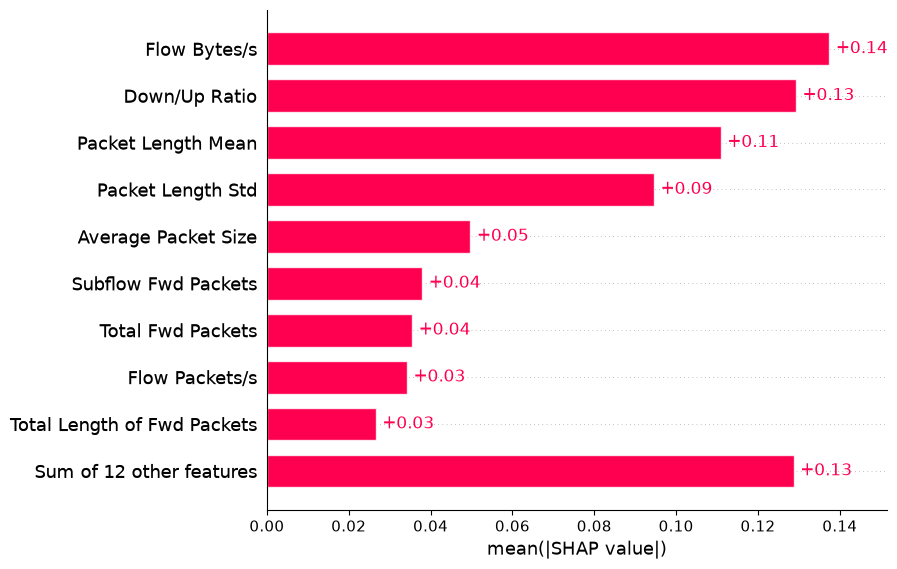

In [25]:
explainer_mlp = shap.PermutationExplainer(modelo_mlp.predict_proba,shap.sample(x_treino_scaled, 50, random_state=42))
shap_values_mlp = explainer_mlp(amostra_100)

shap.plots.bar(shap_values_mlp[:, :, 1])